In [43]:
import pandas as pd
import numpy as np
import plotly.express as px

In [44]:
df = pd.read_excel("../data/raw/final_dataset.xlsx")

df.head()

,Time,Injection_Rate,Injection_Pressure
0,2020-01-01 04:50:03.011,87.396016,10.085800
1,2020-01-01 12:50:01.864,102.519127,10.962814
2,2020-01-01 20:50:01.864,102.519127,11.182083
3,2020-01-02 04:50:01.864,102.519127,10.743561
4,2020-01-02 12:40:03.360,118.256877,10.962814


In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Time                1303 non-null   datetime64[us]
 1   Injection_Rate      1303 non-null   float64       
 2   Injection_Pressure  1303 non-null   float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 30.7 KB


In [46]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
Time                  0
Injection_Rate        0
Injection_Pressure    0
dtype: int64

Duplicate rows:
0


In [47]:
df[['Injection_Rate', 'Injection_Pressure']].describe()

,Injection_Rate,Injection_Pressure
count,1303.000000,1303.000000
mean,591.978344,21.025732
std,451.635332,14.555152
min,0.000000,2.631073
25%,295.678178,4.604385
50%,559.558553,23.679688
75%,842.514906,32.669205
max,7597.284004,178.474747


In [48]:
fig = px.line(
    df,
    x='Time',
    y='Injection_Rate',
    title='Water Injection Rate Over Time',
    labels={
        'Time': 'Time',
        'Injection_Rate': 'Injection Rate'
    }
)

fig.show()

In [49]:
fig = px.line(
    df,
    x='Time',
    y='Injection_Pressure',
    title='Water Injection Pressure Over Time',
    labels={
        'Time': 'Time',
        'Injection_Pressure': 'Injection Pressure'
    }
)

fig.show()

In [50]:
fig = px.scatter(
    df,
    x='Injection_Rate',
    y='Injection_Pressure',
    title='Injection Rate vs Injection Pressure',
    labels={
        'Injection_Rate': 'Injection Rate',
        'Injection_Pressure': 'Injection Pressure'
    }
)

fig.show()

In [51]:
features = df[['Injection_Rate', 'Injection_Pressure']]

features.head()

,Injection_Rate,Injection_Pressure
0,87.396016,10.085800
1,102.519127,10.962814
2,102.519127,11.182083
3,102.519127,10.743561
4,118.256877,10.962814


In [52]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    contamination=0.05,
    random_state=42
)

model.fit(features)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [53]:
df['Anomaly'] = model.predict(features)

df['Anomaly'].value_counts()

Anomaly
 1    1237
-1      66
Name: count, dtype: int64

In [54]:
anomalies = df[df['Anomaly'] == -1]

anomalies[['Time', 'Injection_Rate', 'Injection_Pressure']].head(20)

,Time,Injection_Rate,Injection_Pressure
106,2020-01-31 20:00:02.842,261.270145,3.069595
107,2020-02-01 04:00:02.842,261.270145,2.631073
108,2020-02-01 05:00:00.312,2.180472,3.069595
109,2020-02-01 13:00:00.312,2.180472,3.069595
110,2020-02-01 21:00:00.312,2.180472,7.016205
111,2020-02-02 05:00:00.312,2.180472,21.267868
112,2020-02-02 05:00:01.685,7597.284004,21.267868
113,2020-02-02 13:00:01.685,7597.284004,30.038132
114,2020-02-02 21:00:01.685,7597.284004,33.984741
232,2020-03-06 05:00:03.372,0.000000,26.530029


In [55]:
df['Anomaly_Score'] = model.decision_function(features)

df[['Time', 'Injection_Rate', 'Injection_Pressure', 'Anomaly', 'Anomaly_Score']].sort_values(
    'Anomaly_Score'
).head(20)

,Time,Injection_Rate,Injection_Pressure,Anomaly,Anomaly_Score
112,2020-02-02 05:00:01.685,7597.284004,21.267868,-1,-0.144971
113,2020-02-02 13:00:01.685,7597.284004,30.038132,-1,-0.135073
893,2020-09-09 04:00:02.454,0.000000,178.474747,-1,-0.131719
114,2020-02-02 21:00:01.685,7597.284004,33.984741,-1,-0.116101
552,2020-06-06 04:00:03.068,1035.160489,44.289795,-1,-0.085393
551,2020-06-05 20:00:03.068,1035.160489,44.070541,-1,-0.079141
549,2020-06-05 04:00:03.068,1035.160489,43.851288,-1,-0.075596
550,2020-06-05 12:00:03.068,1035.160489,43.851288,-1,-0.075596
109,2020-02-01 13:00:00.312,2.180472,3.069595,-1,-0.073871
108,2020-02-01 05:00:00.312,2.180472,3.069595,-1,-0.073871


In [56]:
print("Model offset:", model.offset_)

print("\nPrediction vs score check:")

check = df[['Anomaly', 'Anomaly_Score']].copy()

check['Expected_Anomaly'] = np.where(
    check['Anomaly_Score'] < 0,
    -1,
    1
)

print(check.head(20))

print("\nNumber of mismatches:")
print((check['Anomaly'] != check['Expected_Anomaly']).sum())

Model offset: -0.5777007504108969

Prediction vs score check:
    Anomaly  Anomaly_Score  Expected_Anomaly
0         1       0.011238                 1
1         1       0.011718                 1
2         1       0.005066                 1
3         1       0.024987                 1
4         1       0.027097                 1
5         1       0.041471                 1
6         1       0.039277                 1
7         1       0.051356                 1
8         1       0.051356                 1
9         1       0.056082                 1
10        1       0.053691                 1
11        1       0.058396                 1
12        1       0.055390                 1
13        1       0.058464                 1
14        1       0.061802                 1
15        1       0.058464                 1
16        1       0.062614                 1
17        1       0.074986                 1
18        1       0.065286                 1
19        1       0.070485            

In [57]:
check = df[['Anomaly', 'Anomaly_Score']].copy()

check['Expected_Anomaly'] = np.where(
    check['Anomaly_Score'] < model.offset_,
    -1,
    1
)

print("Model offset:", model.offset_)
print("\nNumber of mismatches:")
print((check['Anomaly'] != check['Expected_Anomaly']).sum())

Model offset: -0.5777007504108969

Number of mismatches:
66


In [58]:
# Recalculate both prediction and score from the current model
new_prediction = model.predict(features)
new_score = model.decision_function(features)

# Check whether the prediction agrees with the score
expected_prediction = np.where(new_score < 0, -1, 1)

print("Prediction mismatches:", (new_prediction != expected_prediction).sum())
print("Anomalies detected:", (new_prediction == -1).sum())
print("Normal observations:", (new_prediction == 1).sum())

Prediction mismatches: 0
Anomalies detected: 66
Normal observations: 1237


In [59]:
df['Anomaly'] = new_prediction
df['Anomaly_Score'] = new_score

df.head()

,Time,Injection_Rate,Injection_Pressure,Anomaly,Anomaly_Score
0,2020-01-01 04:50:03.011,87.396016,10.085800,1,0.011238
1,2020-01-01 12:50:01.864,102.519127,10.962814,1,0.011718
2,2020-01-01 20:50:01.864,102.519127,11.182083,1,0.005066
3,2020-01-02 04:50:01.864,102.519127,10.743561,1,0.024987
4,2020-01-02 12:40:03.360,118.256877,10.962814,1,0.027097


In [60]:
# Check the anomaly observations
anomalies = df[df["Anomaly"] == -1]

print("Number of anomalies:", len(anomalies))
print("\nAnomaly observations:")
display(anomalies)

Number of anomalies: 66

Anomaly observations:


,Time,Injection_Rate,Injection_Pressure,Anomaly,Anomaly_Score
106,2020-01-31 20:00:02.842,261.270145,3.069595,-1,-0.022312
107,2020-02-01 04:00:02.842,261.270145,2.631073,-1,-0.032142
108,2020-02-01 05:00:00.312,2.180472,3.069595,-1,-0.073871
109,2020-02-01 13:00:00.312,2.180472,3.069595,-1,-0.073871
110,2020-02-01 21:00:00.312,2.180472,7.016205,-1,-0.053019
...,...,...,...,...,...
1268,2020-12-21 21:40:00.673,1242.212068,5.042892,-1,-0.003344
1298,2020-12-30 21:00:00.248,1295.495050,3.946609,-1,-0.014390
1299,2020-12-31 05:00:00.248,1295.495050,4.823639,-1,-0.019622
1300,2020-12-31 05:00:02.137,1281.912147,4.823639,-1,-0.010517


In [61]:
# Compare normal observations with anomalies

normal = df[df["Anomaly"] == 1]

print("NORMAL observations")
print(normal[["Injection_Rate", "Injection_Pressure"]].describe())

print("\nANOMALY observations")
print(anomalies[["Injection_Rate", "Injection_Pressure"]].describe())

NORMAL observations
       Injection_Rate  Injection_Pressure
count     1237.000000         1237.000000
mean       581.254979           20.570932
std        290.540960           13.603322
min          0.000000            3.288849
25%        304.738825            4.604385
50%        565.141525           23.460434
75%        838.001172           32.449951
max       1295.495050           44.070541

ANOMALY observations
       Injection_Rate  Injection_Pressure
count       66.000000           66.000000
mean       792.960199           29.549786
std       1561.216343           25.437173
min          0.000000            2.631073
25%         10.711022            5.262146
50%        525.433131           32.230698
75%        964.709915           44.070541
max       7597.284004          178.474747


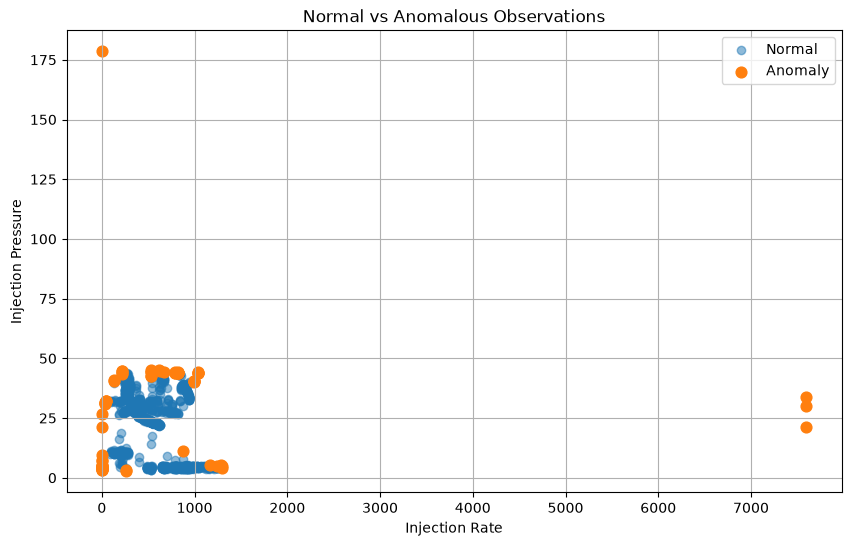

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    normal["Injection_Rate"],
    normal["Injection_Pressure"],
    label="Normal",
    alpha=0.5
)

plt.scatter(
    anomalies["Injection_Rate"],
    anomalies["Injection_Pressure"],
    label="Anomaly",
    s=60
)

plt.xlabel("Injection Rate")
plt.ylabel("Injection Pressure")
plt.title("Normal vs Anomalous Observations")
plt.legend()
plt.grid(True)

plt.show()

In [63]:
# Show the 10 most unusual observations

most_anomalous = df.sort_values(
    by="Anomaly_Score"
).head(10)

display(
    most_anomalous[
        [
            "Time",
            "Injection_Rate",
            "Injection_Pressure",
            "Anomaly_Score"
        ]
    ]
)

,Time,Injection_Rate,Injection_Pressure,Anomaly_Score
112,2020-02-02 05:00:01.685,7597.284004,21.267868,-0.144971
113,2020-02-02 13:00:01.685,7597.284004,30.038132,-0.135073
893,2020-09-09 04:00:02.454,0.000000,178.474747,-0.131719
114,2020-02-02 21:00:01.685,7597.284004,33.984741,-0.116101
552,2020-06-06 04:00:03.068,1035.160489,44.289795,-0.085393
551,2020-06-05 20:00:03.068,1035.160489,44.070541,-0.079141
549,2020-06-05 04:00:03.068,1035.160489,43.851288,-0.075596
550,2020-06-05 12:00:03.068,1035.160489,43.851288,-0.075596
109,2020-02-01 13:00:00.312,2.180472,3.069595,-0.073871
108,2020-02-01 05:00:00.312,2.180472,3.069595,-0.073871


In [64]:
from sklearn.ensemble import IsolationForest

# Test the model with different random seeds
seeds = [1, 10, 42, 100, 2026]

for seed in seeds:
    test_model = IsolationForest(
        contamination=0.05,
        random_state=seed
    )
    
    test_model.fit(features)
    predictions = test_model.predict(features)
    
    anomaly_count = (predictions == -1).sum()
    
    print(f"Random State {seed}: {anomaly_count} anomalies")

Random State 1: 64 anomalies
Random State 10: 66 anomalies
Random State 42: 66 anomalies
Random State 100: 66 anomalies
Random State 2026: 66 anomalies


In [65]:
# Test different contamination levels

contamination_values = [0.01, 0.03, 0.05, 0.07, 0.10]

for contamination in contamination_values:
    test_model = IsolationForest(
        contamination=contamination,
        random_state=42
    )

    test_model.fit(features)
    predictions = test_model.predict(features)

    anomaly_count = (predictions == -1).sum()

    print(
        f"Contamination {contamination:.0%}: "
        f"{anomaly_count} anomalies "
        f"({anomaly_count / len(df) * 100:.2f}%)"
    )

Contamination 1%: 13 anomalies (1.00%)
Contamination 3%: 40 anomalies (3.07%)
Contamination 5%: 66 anomalies (5.07%)
Contamination 7%: 90 anomalies (6.91%)
Contamination 10%: 130 anomalies (9.98%)


In [66]:
fig = px.scatter(
    df,
    x='Injection_Rate',
    y='Injection_Pressure',
    color='Anomaly',
    title='Isolation Forest Anomaly Detection',
    labels={
        'Injection_Rate': 'Injection Rate',
        'Injection_Pressure': 'Injection Pressure',
        'Anomaly': 'ML Classification'
    },
    hover_data=['Time', 'Anomaly_Score']
)

fig.show()

In [67]:
df['Status'] = df['Anomaly'].map({
    1: 'Normal',
    -1: 'Anomaly'
})

fig = px.scatter(
    df,
    x='Injection_Rate',
    y='Injection_Pressure',
    color='Status',
    title='Isolation Forest Anomaly Detection',
    labels={
        'Injection_Rate': 'Injection Rate',
        'Injection_Pressure': 'Injection Pressure',
        'Status': 'ML Classification'
    },
    hover_data=[
        'Time',
        'Injection_Rate',
        'Injection_Pressure',
        'Anomaly_Score'
    ]
)

fig.show()

In [68]:
fig = px.scatter(
    df,
    x='Time',
    y='Injection_Rate',
    color='Status',
    title='Injection Rate with Detected Anomalies Over Time',
    labels={
        'Time': 'Time',
        'Injection_Rate': 'Injection Rate',
        'Status': 'ML Classification'
    },
    hover_data=[
        'Injection_Pressure',
        'Anomaly_Score'
    ]
)

fig.show()

In [69]:
fig = px.scatter(
    df,
    x='Time',
    y='Injection_Pressure',
    color='Status',
    title='Injection Pressure with Detected Anomalies Over Time',
    labels={
        'Time': 'Time',
        'Injection_Pressure': 'Injection Pressure',
        'Status': 'ML Classification'
    },
    hover_data=[
        'Injection_Rate',
        'Anomaly_Score'
    ]
)

fig.show()

In [70]:
# Calculate normal operating ranges
normal_data = df[df['Anomaly'] == 1]

rate_low = normal_data['Injection_Rate'].quantile(0.05)
rate_high = normal_data['Injection_Rate'].quantile(0.95)

pressure_low = normal_data['Injection_Pressure'].quantile(0.05)
pressure_high = normal_data['Injection_Pressure'].quantile(0.95)


def generate_alert(row):
    if row['Anomaly'] == 1:
        return 'Normal', 'No action required'
    
    reasons = []
    
    if row['Injection_Rate'] < rate_low:
        reasons.append('unusually low injection rate')
    elif row['Injection_Rate'] > rate_high:
        reasons.append('unusually high injection rate')
    
    if row['Injection_Pressure'] < pressure_low:
        reasons.append('unusually low injection pressure')
    elif row['Injection_Pressure'] > pressure_high:
        reasons.append('unusually high injection pressure')
    
    if reasons:
        reason_text = ' and '.join(reasons)
        message = f'Anomalous behaviour detected: {reason_text}.'
    else:
        message = 'Anomalous combination of injection rate and pressure detected.'
    
    action = 'Review the corresponding operating condition and verify the relevant measurements.'
    
    return message, action


alerts = df.apply(generate_alert, axis=1)

df['Notification'] = [alert[0] for alert in alerts]
df['Suggested_Action'] = [alert[1] for alert in alerts]

df[df['Anomaly'] == -1][
    ['Time', 'Injection_Rate', 'Injection_Pressure',
     'Anomaly_Score', 'Notification', 'Suggested_Action']
].head(10)

,Time,Injection_Rate,Injection_Pressure,Anomaly_Score,Notification,Suggested_Action
106,2020-01-31 20:00:02.842,261.270145,3.069595,-0.022312,Anomalous behaviour detected: unusually low in...,Review the corresponding operating condition a...
107,2020-02-01 04:00:02.842,261.270145,2.631073,-0.032142,Anomalous behaviour detected: unusually low in...,Review the corresponding operating condition a...
108,2020-02-01 05:00:00.312,2.180472,3.069595,-0.073871,Anomalous behaviour detected: unusually low in...,Review the corresponding operating condition a...
109,2020-02-01 13:00:00.312,2.180472,3.069595,-0.073871,Anomalous behaviour detected: unusually low in...,Review the corresponding operating condition a...
110,2020-02-01 21:00:00.312,2.180472,7.016205,-0.053019,Anomalous behaviour detected: unusually low in...,Review the corresponding operating condition a...
111,2020-02-02 05:00:00.312,2.180472,21.267868,-0.068745,Anomalous behaviour detected: unusually low in...,Review the corresponding operating condition a...
112,2020-02-02 05:00:01.685,7597.284004,21.267868,-0.144971,Anomalous behaviour detected: unusually high i...,Review the corresponding operating condition a...
113,2020-02-02 13:00:01.685,7597.284004,30.038132,-0.135073,Anomalous behaviour detected: unusually high i...,Review the corresponding operating condition a...
114,2020-02-02 21:00:01.685,7597.284004,33.984741,-0.116101,Anomalous behaviour detected: unusually high i...,Review the corresponding operating condition a...
232,2020-03-06 05:00:03.372,0.000000,26.530029,-0.029215,Anomalous behaviour detected: unusually low in...,Review the corresponding operating condition a...


In [71]:
def generate_alert(row):
    if row['Anomaly'] == 1:
        return (
            'Normal',
            'No action required'
        )

    rate = row['Injection_Rate']
    pressure = row['Injection_Pressure']

    # Check whether each variable is unusually high or low
    high_rate = rate > rate_high
    low_rate = rate < rate_low
    high_pressure = pressure > pressure_high
    low_pressure = pressure < pressure_low

    # 1. Very low rate + very high pressure
    if low_rate and high_pressure:
        notification = (
            'Anomalous behaviour detected: '
            'very low injection rate with unusually high pressure.'
        )
        action = (
            'Review the pressure and flow measurements '
            'and verify the injection system condition.'
        )

    # 2. Very high rate + very low pressure
    elif high_rate and low_pressure:
        notification = (
            'Anomalous behaviour detected: '
            'very high injection rate with unusually low pressure.'
        )
        action = (
            'Verify the injection-rate measurement '
            'and review the flow-control condition.'
        )

    # 3. High rate + high pressure
    elif high_rate and high_pressure:
        notification = (
            'Anomalous behaviour detected: '
            'high injection rate and high injection pressure.'
        )
        action = (
            'Review both injection rate and pressure '
            'and verify the current operating condition.'
        )

    # 4. Low rate + low pressure
    elif low_rate and low_pressure:
        notification = (
            'Anomalous behaviour detected: '
            'low injection rate and low injection pressure.'
        )
        action = (
            'Check the injection flow and pressure '
            'and verify the relevant equipment conditions.'
        )

    # 5. High injection rate only
    elif high_rate:
        notification = (
            'Anomalous behaviour detected: '
            'unusually high injection rate.'
        )
        action = (
            'Verify the injection-rate measurement '
            'and review the flow-control setting.'
        )

    # 6. Low injection rate only
    elif low_rate:
        notification = (
            'Anomalous behaviour detected: '
            'unusually low injection rate.'
        )
        action = (
            'Check the injection flow and verify '
            'the relevant pump and measurement conditions.'
        )

    # 7. High pressure only
    elif high_pressure:
        notification = (
            'Anomalous behaviour detected: '
            'unusually high injection pressure.'
        )
        action = (
            'Review the pressure condition and verify '
            'the pressure measurement and equipment status.'
        )

    # 8. Low pressure only
    elif low_pressure:
        notification = (
            'Anomalous behaviour detected: '
            'unusually low injection pressure.'
        )
        action = (
            'Check the injection pressure and verify '
            'the relevant pump and flow conditions.'
        )

    # 9. Anomaly detected but does not match the rules above
    else:
        notification = (
            'Anomalous combination of injection rate '
            'and pressure detected.'
        )
        action = (
            'Review the injection-rate and pressure trends '
            'around this timestamp.'
        )

    return notification, action


# Generate notifications and suggested actions
alerts = df.apply(generate_alert, axis=1)

df['Notification'] = [alert[0] for alert in alerts]
df['Suggested_Action'] = [alert[1] for alert in alerts]


# Display the detected anomalies
df[df['Anomaly'] == -1][
    [
        'Time',
        'Injection_Rate',
        'Injection_Pressure',
        'Anomaly_Score',
        'Notification',
        'Suggested_Action'
    ]
].head(20)

,Time,Injection_Rate,Injection_Pressure,Anomaly_Score,Notification,Suggested_Action
106,2020-01-31 20:00:02.842,261.270145,3.069595,-0.022312,Anomalous behaviour detected: unusually low in...,Check the injection pressure and verify the re...
107,2020-02-01 04:00:02.842,261.270145,2.631073,-0.032142,Anomalous behaviour detected: unusually low in...,Check the injection pressure and verify the re...
108,2020-02-01 05:00:00.312,2.180472,3.069595,-0.073871,Anomalous behaviour detected: low injection ra...,Check the injection flow and pressure and veri...
109,2020-02-01 13:00:00.312,2.180472,3.069595,-0.073871,Anomalous behaviour detected: low injection ra...,Check the injection flow and pressure and veri...
110,2020-02-01 21:00:00.312,2.180472,7.016205,-0.053019,Anomalous behaviour detected: unusually low in...,Check the injection flow and verify the releva...
111,2020-02-02 05:00:00.312,2.180472,21.267868,-0.068745,Anomalous behaviour detected: unusually low in...,Check the injection flow and verify the releva...
112,2020-02-02 05:00:01.685,7597.284004,21.267868,-0.144971,Anomalous behaviour detected: unusually high i...,Verify the injection-rate measurement and revi...
113,2020-02-02 13:00:01.685,7597.284004,30.038132,-0.135073,Anomalous behaviour detected: unusually high i...,Verify the injection-rate measurement and revi...
114,2020-02-02 21:00:01.685,7597.284004,33.984741,-0.116101,Anomalous behaviour detected: unusually high i...,Verify the injection-rate measurement and revi...
232,2020-03-06 05:00:03.372,0.000000,26.530029,-0.029215,Anomalous behaviour detected: unusually low in...,Check the injection flow and verify the releva...


In [72]:
df.loc[
    (df['Injection_Rate'] == 0) &
    (df['Injection_Pressure'] > 100),
    [
        'Time',
        'Injection_Rate',
        'Injection_Pressure',
        'Anomaly',
        'Anomaly_Score',
        'Notification',
        'Suggested_Action'
    ]
]

,Time,Injection_Rate,Injection_Pressure,Anomaly,Anomaly_Score,Notification,Suggested_Action
893,2020-09-09 04:00:02.454,0.0,178.474747,-1,-0.131719,Anomalous behaviour detected: very low injecti...,Review the pressure and flow measurements and ...


In [73]:
# Count the different types of recommendations
df[df['Anomaly'] == -1]['Notification'].value_counts()

Notification
Anomalous behaviour detected: unusually high injection pressure.                       20
Anomalous behaviour detected: unusually low injection rate.                            17
Anomalous behaviour detected: unusually high injection rate.                            9
Anomalous behaviour detected: low injection rate and low injection pressure.            6
Anomalous combination of injection rate and pressure detected.                          5
Anomalous behaviour detected: high injection rate and high injection pressure.          4
Anomalous behaviour detected: very low injection rate with unusually high pressure.     3
Anomalous behaviour detected: unusually low injection pressure.                         2
Name: count, dtype: int64

In [74]:
# Check that every anomaly has a notification and suggested action

anomalies = df[df['Anomaly'] == -1]

print("Total anomalies:", len(anomalies))
print("Missing notifications:", anomalies['Notification'].isna().sum())
print("Missing suggested actions:", anomalies['Suggested_Action'].isna().sum())

Total anomalies: 66
Missing notifications: 0
Missing suggested actions: 0


In [75]:
# Calculate expected operating values from normal observations

normal_data = df[df['Anomaly'] == 1]

expected_rate = normal_data['Injection_Rate'].median()
expected_pressure = normal_data['Injection_Pressure'].median()

print("Expected Injection Rate:", round(expected_rate, 2))
print("Expected Injection Pressure:", round(expected_pressure, 2))

Expected Injection Rate: 565.14
Expected Injection Pressure: 23.46


In [76]:
# Calculate actual values and deviation from expected behaviour

df['Expected_Rate'] = expected_rate
df['Expected_Pressure'] = expected_pressure

df['Rate_Deviation'] = (
    df['Injection_Rate'] - df['Expected_Rate']
)

df['Pressure_Deviation'] = (
    df['Injection_Pressure'] - df['Expected_Pressure']
)

# Calculate percentage deviation
df['Rate_Deviation_%'] = (
    df['Rate_Deviation'] / df['Expected_Rate']
) * 100

df['Pressure_Deviation_%'] = (
    df['Pressure_Deviation'] / df['Expected_Pressure']
) * 100


# Display the results
df[
    [
        'Time',
        'Injection_Rate',
        'Expected_Rate',
        'Rate_Deviation',
        'Rate_Deviation_%',
        'Injection_Pressure',
        'Expected_Pressure',
        'Pressure_Deviation',
        'Pressure_Deviation_%'
    ]
].head(10)

,Time,Injection_Rate,Expected_Rate,Rate_Deviation,Rate_Deviation_%,Injection_Pressure,Expected_Pressure,Pressure_Deviation,Pressure_Deviation_%
0,2020-01-01 04:50:03.011,87.396016,565.141525,-477.745509,-84.535552,10.085800,23.460434,-13.374634,-57.009320
1,2020-01-01 12:50:01.864,102.519127,565.141525,-462.622398,-81.859566,10.962814,23.460434,-12.497620,-53.271051
2,2020-01-01 20:50:01.864,102.519127,565.141525,-462.622398,-81.859566,11.182083,23.460434,-12.278351,-52.336418
3,2020-01-02 04:50:01.864,102.519127,565.141525,-462.622398,-81.859566,10.743561,23.460434,-12.716873,-54.205618
4,2020-01-02 12:40:03.360,118.256877,565.141525,-446.884648,-79.074821,10.962814,23.460434,-12.497620,-53.271051
5,2020-01-02 20:40:03.360,118.256877,565.141525,-446.884648,-79.074821,10.305054,23.460434,-13.155380,-56.074752
6,2020-01-03 04:40:03.360,118.256877,565.141525,-446.884648,-79.074821,10.743561,23.460434,-12.716873,-54.205618
7,2020-01-03 05:00:02.233,127.992948,565.141525,-437.148578,-77.352054,10.085800,23.460434,-13.374634,-57.009320
8,2020-01-03 13:00:02.233,127.992948,565.141525,-437.148578,-77.352054,10.085800,23.460434,-13.374634,-57.009320
9,2020-01-03 21:00:02.233,127.992948,565.141525,-437.148578,-77.352054,10.305054,23.460434,-13.155380,-56.074752


In [77]:
# Calculate deviation from expected operating conditions

df['Rate_Deviation'] = (
    df['Injection_Rate'] - df['Expected_Rate']
)

df['Rate_Deviation_%'] = (
    df['Rate_Deviation'] / df['Expected_Rate']
) * 100

df['Pressure_Deviation'] = (
    df['Injection_Pressure'] - df['Expected_Pressure']
)

df['Pressure_Deviation_%'] = (
    df['Pressure_Deviation'] / df['Expected_Pressure']
) * 100

df[
    [
        'Time',
        'Injection_Rate',
        'Expected_Rate',
        'Rate_Deviation',
        'Rate_Deviation_%',
        'Injection_Pressure',
        'Expected_Pressure',
        'Pressure_Deviation',
        'Pressure_Deviation_%'
    ]
].head(10)

,Time,Injection_Rate,Expected_Rate,Rate_Deviation,Rate_Deviation_%,Injection_Pressure,Expected_Pressure,Pressure_Deviation,Pressure_Deviation_%
0,2020-01-01 04:50:03.011,87.396016,565.141525,-477.745509,-84.535552,10.085800,23.460434,-13.374634,-57.009320
1,2020-01-01 12:50:01.864,102.519127,565.141525,-462.622398,-81.859566,10.962814,23.460434,-12.497620,-53.271051
2,2020-01-01 20:50:01.864,102.519127,565.141525,-462.622398,-81.859566,11.182083,23.460434,-12.278351,-52.336418
3,2020-01-02 04:50:01.864,102.519127,565.141525,-462.622398,-81.859566,10.743561,23.460434,-12.716873,-54.205618
4,2020-01-02 12:40:03.360,118.256877,565.141525,-446.884648,-79.074821,10.962814,23.460434,-12.497620,-53.271051
5,2020-01-02 20:40:03.360,118.256877,565.141525,-446.884648,-79.074821,10.305054,23.460434,-13.155380,-56.074752
6,2020-01-03 04:40:03.360,118.256877,565.141525,-446.884648,-79.074821,10.743561,23.460434,-12.716873,-54.205618
7,2020-01-03 05:00:02.233,127.992948,565.141525,-437.148578,-77.352054,10.085800,23.460434,-13.374634,-57.009320
8,2020-01-03 13:00:02.233,127.992948,565.141525,-437.148578,-77.352054,10.085800,23.460434,-13.374634,-57.009320
9,2020-01-03 21:00:02.233,127.992948,565.141525,-437.148578,-77.352054,10.305054,23.460434,-13.155380,-56.074752


In [78]:
# Classify the severity of operating-condition deviation

def classify_deviation(deviation_pct):
    deviation = abs(deviation_pct)

    if deviation <= 10:
        return "Normal"
    elif deviation <= 25:
        return "Slight Deviation"
    elif deviation <= 50:
        return "Significant Deviation"
    else:
        return "Critical Deviation"


df['Rate_Status'] = df['Rate_Deviation_%'].apply(classify_deviation)
df['Pressure_Status'] = df['Pressure_Deviation_%'].apply(classify_deviation)

df[
    [
        'Time',
        'Injection_Rate',
        'Expected_Rate',
        'Rate_Deviation_%',
        'Rate_Status',
        'Injection_Pressure',
        'Expected_Pressure',
        'Pressure_Deviation_%',
        'Pressure_Status'
    ]
].head(10)

,Time,Injection_Rate,Expected_Rate,Rate_Deviation_%,Rate_Status,Injection_Pressure,Expected_Pressure,Pressure_Deviation_%,Pressure_Status
0,2020-01-01 04:50:03.011,87.396016,565.141525,-84.535552,Critical Deviation,10.085800,23.460434,-57.009320,Critical Deviation
1,2020-01-01 12:50:01.864,102.519127,565.141525,-81.859566,Critical Deviation,10.962814,23.460434,-53.271051,Critical Deviation
2,2020-01-01 20:50:01.864,102.519127,565.141525,-81.859566,Critical Deviation,11.182083,23.460434,-52.336418,Critical Deviation
3,2020-01-02 04:50:01.864,102.519127,565.141525,-81.859566,Critical Deviation,10.743561,23.460434,-54.205618,Critical Deviation
4,2020-01-02 12:40:03.360,118.256877,565.141525,-79.074821,Critical Deviation,10.962814,23.460434,-53.271051,Critical Deviation
5,2020-01-02 20:40:03.360,118.256877,565.141525,-79.074821,Critical Deviation,10.305054,23.460434,-56.074752,Critical Deviation
6,2020-01-03 04:40:03.360,118.256877,565.141525,-79.074821,Critical Deviation,10.743561,23.460434,-54.205618,Critical Deviation
7,2020-01-03 05:00:02.233,127.992948,565.141525,-77.352054,Critical Deviation,10.085800,23.460434,-57.009320,Critical Deviation
8,2020-01-03 13:00:02.233,127.992948,565.141525,-77.352054,Critical Deviation,10.085800,23.460434,-57.009320,Critical Deviation
9,2020-01-03 21:00:02.233,127.992948,565.141525,-77.352054,Critical Deviation,10.305054,23.460434,-56.074752,Critical Deviation


In [79]:
# Create an overall operating status for each observation

def overall_status(row):
    statuses = [row['Rate_Status'], row['Pressure_Status']]
    
    if 'Critical Deviation' in statuses:
        return 'Critical'
    elif 'Significant Deviation' in statuses:
        return 'Significant'
    elif 'Slight Deviation' in statuses:
        return 'Slight'
    else:
        return 'Normal'


df['Overall_Status'] = df.apply(overall_status, axis=1)

df[
    [
        'Time',
        'Injection_Rate',
        'Expected_Rate',
        'Rate_Deviation_%',
        'Rate_Status',
        'Injection_Pressure',
        'Expected_Pressure',
        'Pressure_Deviation_%',
        'Pressure_Status',
        'Overall_Status'
    ]
].head(10)

,Time,Injection_Rate,Expected_Rate,Rate_Deviation_%,Rate_Status,Injection_Pressure,Expected_Pressure,Pressure_Deviation_%,Pressure_Status,Overall_Status
0,2020-01-01 04:50:03.011,87.396016,565.141525,-84.535552,Critical Deviation,10.085800,23.460434,-57.009320,Critical Deviation,Critical
1,2020-01-01 12:50:01.864,102.519127,565.141525,-81.859566,Critical Deviation,10.962814,23.460434,-53.271051,Critical Deviation,Critical
2,2020-01-01 20:50:01.864,102.519127,565.141525,-81.859566,Critical Deviation,11.182083,23.460434,-52.336418,Critical Deviation,Critical
3,2020-01-02 04:50:01.864,102.519127,565.141525,-81.859566,Critical Deviation,10.743561,23.460434,-54.205618,Critical Deviation,Critical
4,2020-01-02 12:40:03.360,118.256877,565.141525,-79.074821,Critical Deviation,10.962814,23.460434,-53.271051,Critical Deviation,Critical
5,2020-01-02 20:40:03.360,118.256877,565.141525,-79.074821,Critical Deviation,10.305054,23.460434,-56.074752,Critical Deviation,Critical
6,2020-01-03 04:40:03.360,118.256877,565.141525,-79.074821,Critical Deviation,10.743561,23.460434,-54.205618,Critical Deviation,Critical
7,2020-01-03 05:00:02.233,127.992948,565.141525,-77.352054,Critical Deviation,10.085800,23.460434,-57.009320,Critical Deviation,Critical
8,2020-01-03 13:00:02.233,127.992948,565.141525,-77.352054,Critical Deviation,10.085800,23.460434,-57.009320,Critical Deviation,Critical
9,2020-01-03 21:00:02.233,127.992948,565.141525,-77.352054,Critical Deviation,10.305054,23.460434,-56.074752,Critical Deviation,Critical


In [80]:
# Generate notification and suggested action based on the detected condition


def generate_notification(row):
    rate = row["Injection_Rate"]
    expected_rate = row["Expected_Rate"]
    pressure = row["Injection_Pressure"]
    expected_pressure = row["Expected_Pressure"]

    rate_status = row["Rate_Status"]
    pressure_status = row["Pressure_Status"]

    # Only classify variables with a detected deviation
    rate_deviates = "Deviation" in str(rate_status)
    pressure_deviates = "Deviation" in str(pressure_status)

    rate_low = rate_deviates and rate < expected_rate
    rate_high = rate_deviates and rate > expected_rate
    pressure_low = pressure_deviates and pressure < expected_pressure
    pressure_high = pressure_deviates and pressure > expected_pressure

    # Check both variables together first
    if rate_low and pressure_low:
        return "Very low injection rate and pressure"

    elif rate_high and pressure_high:
        return "Very high injection rate and pressure"

    elif rate_low and pressure_high:
        return "Low injection rate and high injection pressure"

    elif rate_high and pressure_low:
        return "High injection rate and low injection pressure"

    # Then check individual variables
    elif rate_low:
        return "Unusually low injection rate"

    elif rate_high:
        return "Unusually high injection rate"

    elif pressure_low:
        return "Unusually low injection pressure"

    elif pressure_high:
        return "Unusually high injection pressure"

    return "Other unusual pattern"




def generate_action(row):
    rate = row['Injection_Rate']
    pressure = row['Injection_Pressure']
    expected_rate = row['Expected_Rate']
    expected_pressure = row['Expected_Pressure']

    rate_status = row['Rate_Status']
    pressure_status = row['Pressure_Status']

    rate_deviates = rate_status in [
        'Significant Deviation', 'Critical Deviation'
    ]
    pressure_deviates = pressure_status in [
        'Significant Deviation', 'Critical Deviation'
    ]

    rate_low = rate_deviates and rate < expected_rate
    rate_high = rate_deviates and rate > expected_rate
    pressure_low = pressure_deviates and pressure < expected_pressure
    pressure_high = pressure_deviates and pressure > expected_pressure

    # Both injection rate and pressure are unusually low
    if rate_low and pressure_low:
        return (
            "Review injection-rate and pressure trends against "
            "expected operating conditions. Verify sensor readings "
            "and check the water supply and pump operating status."
        )

    # Both injection rate and pressure are unusually high
    elif rate_high and pressure_high:
        return (
            "Compare both readings with approved operating limits. "
            "Verify the measurements and review flow and pressure "
            "control. Escalate any persistent out-of-limit readings."
        )

    # Low rate with high pressure
    elif rate_low and pressure_high:
        return (
            "Review the pressure and flow-rate trends together. "
            "Verify both readings and compare their relationship "
            "with historical behaviour. Recommend further assessment "
            "if the pattern persists."
        )

    # High rate with low pressure
    elif rate_high and pressure_low:
        return (
            "Verify both readings and compare them with historical "
            "trends and approved operating conditions. Escalate "
            "persistent or unexplained deviations for assessment."
        )

    # Unusually low injection rate
    elif rate_low:
        return (
            "Verify the flow-rate reading and compare it with recent "
            "values and the expected operating range. If the decrease "
            "persists, investigate possible operational or "
            "measurement issues."
        )

    # Unusually high injection rate
    elif rate_high:
        return (
            "Confirm the flow-rate reading and compare it with the "
            "approved injection-rate limit and recent trends. "
            "Escalate persistent or out-of-limit readings."
        )

    # Unusually low injection pressure
    elif pressure_low:
        return (
            "Review the pressure trend and verify the sensor reading. "
            "Compare it with expected operating conditions and review "
            "recent operating changes. Recommend further assessment "
            "if the deviation persists."
        )

    # Unusually high injection pressure
    elif pressure_high:
        return (
            "Compare the pressure trend with the approved operating "
            "limit and verify the sensor reading. If the limit is "
            "exceeded, follow site procedures and alert the "
            "responsible operator."
        )

    return (
        "Review the corresponding operating condition and verify "
        "the sensor readings."
    )


df['Notification'] = df.apply(generate_notification, axis=1)
df['Suggested_Action'] = df.apply(generate_action, axis=1)

df[
    [
        'Time',
        'Injection_Rate',
        'Injection_Pressure',
        'Anomaly_Score',
        'Notification',
        'Suggested_Action'
    ]
].loc[df['Anomaly'] == -1].head(20)



df['Notification'] = df.apply(generate_notification, axis=1)
df['Suggested_Action'] = df.apply(generate_action, axis=1)

df[
    [
        'Time',
        'Injection_Rate',
        'Injection_Pressure',
        'Anomaly_Score',
        'Notification',
        'Suggested_Action'
    ]
].loc[df['Anomaly'] == -1].head(20)

,Time,Injection_Rate,Injection_Pressure,Anomaly_Score,Notification,Suggested_Action
106,2020-01-31 20:00:02.842,261.270145,3.069595,-0.022312,Very low injection rate and pressure,Review injection-rate and pressure trends agai...
107,2020-02-01 04:00:02.842,261.270145,2.631073,-0.032142,Very low injection rate and pressure,Review injection-rate and pressure trends agai...
108,2020-02-01 05:00:00.312,2.180472,3.069595,-0.073871,Very low injection rate and pressure,Review injection-rate and pressure trends agai...
109,2020-02-01 13:00:00.312,2.180472,3.069595,-0.073871,Very low injection rate and pressure,Review injection-rate and pressure trends agai...
110,2020-02-01 21:00:00.312,2.180472,7.016205,-0.053019,Very low injection rate and pressure,Review injection-rate and pressure trends agai...
111,2020-02-02 05:00:00.312,2.180472,21.267868,-0.068745,Unusually low injection rate,Verify the flow-rate reading and compare it wi...
112,2020-02-02 05:00:01.685,7597.284004,21.267868,-0.144971,Unusually high injection rate,Confirm the flow-rate reading and compare it w...
113,2020-02-02 13:00:01.685,7597.284004,30.038132,-0.135073,Very high injection rate and pressure,Compare both readings with approved operating ...
114,2020-02-02 21:00:01.685,7597.284004,33.984741,-0.116101,Very high injection rate and pressure,Compare both readings with approved operating ...
232,2020-03-06 05:00:03.372,0.000000,26.530029,-0.029215,Low injection rate and high injection pressure,Verify the flow-rate reading and compare it wi...


In [81]:
# Create a clean dataset for the dashboard

dashboard_data = df[
    [
        'Time',
        'Injection_Rate',
        'Expected_Rate',
        'Rate_Deviation',
        'Rate_Deviation_%',
        'Rate_Status',
        'Injection_Pressure',
        'Expected_Pressure',
        'Pressure_Deviation',
        'Pressure_Deviation_%',
        'Pressure_Status',
        'Overall_Status',
        'Anomaly',
        'Anomaly_Score',
        'Notification',
        'Suggested_Action'
    ]
].copy()

dashboard_data.head()

,Time,Injection_Rate,Expected_Rate,Rate_Deviation,Rate_Deviation_%,Rate_Status,Injection_Pressure,Expected_Pressure,Pressure_Deviation,Pressure_Deviation_%,Pressure_Status,Overall_Status,Anomaly,Anomaly_Score,Notification,Suggested_Action
0,2020-01-01 04:50:03.011,87.396016,565.141525,-477.745509,-84.535552,Critical Deviation,10.085800,23.460434,-13.374634,-57.009320,Critical Deviation,Critical,1,0.011238,Very low injection rate and pressure,Review injection-rate and pressure trends agai...
1,2020-01-01 12:50:01.864,102.519127,565.141525,-462.622398,-81.859566,Critical Deviation,10.962814,23.460434,-12.497620,-53.271051,Critical Deviation,Critical,1,0.011718,Very low injection rate and pressure,Review injection-rate and pressure trends agai...
2,2020-01-01 20:50:01.864,102.519127,565.141525,-462.622398,-81.859566,Critical Deviation,11.182083,23.460434,-12.278351,-52.336418,Critical Deviation,Critical,1,0.005066,Very low injection rate and pressure,Review injection-rate and pressure trends agai...
3,2020-01-02 04:50:01.864,102.519127,565.141525,-462.622398,-81.859566,Critical Deviation,10.743561,23.460434,-12.716873,-54.205618,Critical Deviation,Critical,1,0.024987,Very low injection rate and pressure,Review injection-rate and pressure trends agai...
4,2020-01-02 12:40:03.360,118.256877,565.141525,-446.884648,-79.074821,Critical Deviation,10.962814,23.460434,-12.497620,-53.271051,Critical Deviation,Critical,1,0.027097,Very low injection rate and pressure,Review injection-rate and pressure trends agai...


In [82]:
print("Dashboard dataset shape:", dashboard_data.shape)
print("\nColumns:")
print(dashboard_data.columns.tolist())

Dashboard dataset shape: (1303, 16)

Columns:
['Time', 'Injection_Rate', 'Expected_Rate', 'Rate_Deviation', 'Rate_Deviation_%', 'Rate_Status', 'Injection_Pressure', 'Expected_Pressure', 'Pressure_Deviation', 'Pressure_Deviation_%', 'Pressure_Status', 'Overall_Status', 'Anomaly', 'Anomaly_Score', 'Notification', 'Suggested_Action']


In [83]:
# Save the dashboard-ready dataset

output_path = "../data/processed/dashboard_data.xlsx"

dashboard_data.to_excel(output_path, index=False)

print("Dashboard dataset saved successfully!")
print(output_path)

Dashboard dataset saved successfully!
../data/processed/dashboard_data.xlsx


In [84]:
import joblib

# Save the trained Isolation Forest model
model_path = "../models/isolation_forest_model.pkl"

joblib.dump(model, model_path)

print("Isolation Forest model saved successfully!")
print(model_path)

Isolation Forest model saved successfully!
../models/isolation_forest_model.pkl
